In [1]:
# ============================================================
# STEP 2 - LINK PREDICTION ON SYNTHETIC GRAPHS
# Adamic-Adar + NSUM target number of edges
# ============================================================

import os
import glob
import pickle
import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
from tqdm import tqdm
import seaborn as sns


# ------------------------------------------------------------
# 1. Load original graph
# ------------------------------------------------------------

def load_graph(edges_path):
    edges_df = pd.read_csv(edges_path, sep=" ", header=None, names=["from", "to"])

    edges_set = set(tuple(sorted(edge)) for edge in edges_df.to_numpy())
    unique_edges_df = pd.DataFrame(list(edges_set), columns=["source", "target"])

    G = nx.Graph()
    G.add_edges_from(unique_edges_df.to_numpy())

    return G


In [2]:
# ------------------------------------------------------------
# 2. Load synthetic graphs generated in R sparse format
# ------------------------------------------------------------
def load_synthetic_graphs_from_csv_gz(graph_folder, prefix, n_nodes):
    pattern = os.path.join(graph_folder, f"{prefix}_edges_*.csv.gz")
    files = sorted(glob.glob(pattern))

    graphs = []

    for file_path in tqdm(files, desc="Loading synthetic graphs"):
        edges_df = pd.read_csv(file_path)

        G = nx.Graph()
        G.add_nodes_from(range(1, n_nodes + 1))

        if edges_df.shape[0] > 0:
            edge_cols = edges_df.columns[:2]
            edges = list(edges_df[edge_cols].itertuples(index=False, name=None))
            G.add_edges_from(edges)

        graphs.append(G)

    return graphs

### Graph-level metrics

In [3]:
def safe_metric(fn, G):
    try:
        return fn(G)
    except Exception:
        return np.nan


def get_largest_component(G):
    if G.number_of_nodes() == 0:
        return G.copy()

    if nx.is_connected(G):
        return G

    largest_cc = max(nx.connected_components(G), key=len)
    return G.subgraph(largest_cc).copy()


def compute_graph_level_metrics(graphs):
    metric_values = {
        "Number of Nodes": [],
        "Number of Edges": [],
        "Number of Components": [],
        "Largest Component Size": [],
        "Avg Degree": [],
        "Avg Clustering Coeff": [],
        "Avg Path Length": [],
        "Avg Degree Centrality": [],
        "Avg Betweenness Centrality": [],
        "Avg Closeness Centrality": [],
        "Avg Eigenvector Centrality": [],
        "Transitivity": [],
        "Assortativity": [],
    }

    for G in tqdm(graphs, desc="Computing graph-level metrics"):

        # Full graph for almost all metrics
        degrees = [d for _, d in G.degree()]

        deg_cent = nx.degree_centrality(G)
        betw_cent = nx.betweenness_centrality(G)
        clo_cent = nx.closeness_centrality(G)

        try:
            eig_cent = nx.eigenvector_centrality(G, max_iter=1000)
            avg_eig = np.mean(list(eig_cent.values()))
        except Exception:
            avg_eig = np.nan

        # Largest component only for average path length
        G_lcc = get_largest_component(G)

        metric_values["Number of Nodes"].append(G.number_of_nodes())
        metric_values["Number of Edges"].append(G.number_of_edges())
        metric_values["Number of Components"].append(
            nx.number_connected_components(G) if G.number_of_nodes() > 0 else 0
        )
        metric_values["Largest Component Size"].append(G_lcc.number_of_nodes())

        metric_values["Avg Degree"].append(np.mean(degrees) if len(degrees) > 0 else np.nan)
        metric_values["Avg Clustering Coeff"].append(nx.average_clustering(G))
        metric_values["Avg Path Length"].append(
            safe_metric(nx.average_shortest_path_length, G_lcc)
        )

        metric_values["Avg Degree Centrality"].append(np.mean(list(deg_cent.values())) if len(deg_cent) > 0 else np.nan)
        metric_values["Avg Betweenness Centrality"].append(np.mean(list(betw_cent.values())) if len(betw_cent) > 0 else np.nan)
        metric_values["Avg Closeness Centrality"].append(np.mean(list(clo_cent.values())) if len(clo_cent) > 0 else np.nan)
        metric_values["Avg Eigenvector Centrality"].append(avg_eig)

        metric_values["Transitivity"].append(nx.transitivity(G))
        metric_values["Assortativity"].append(
            safe_metric(nx.degree_assortativity_coefficient, G)
        )

    return pd.DataFrame(metric_values)


def compute_true_graph_metrics(G_original):
    degrees = [d for _, d in G_original.degree()]

    deg_cent = nx.degree_centrality(G_original)
    betw_cent = nx.betweenness_centrality(G_original)
    clo_cent = nx.closeness_centrality(G_original)

    try:
        eig_cent = nx.eigenvector_centrality(G_original, max_iter=1000)
        avg_eig = np.mean(list(eig_cent.values()))
    except Exception:
        avg_eig = np.nan

    # Largest component only for average path length
    G_lcc = get_largest_component(G_original)

    return {
        "Number of Nodes": G_original.number_of_nodes(),
        "Number of Edges": G_original.number_of_edges(),
        "Number of Components": (
            nx.number_connected_components(G_original)
            if G_original.number_of_nodes() > 0 else 0
        ),
        "Largest Component Size": G_lcc.number_of_nodes(),

        "Avg Degree": np.mean(degrees) if len(degrees) > 0 else np.nan,
        "Avg Clustering Coeff": nx.average_clustering(G_original),
        "Avg Path Length": safe_metric(nx.average_shortest_path_length, G_lcc),

        "Avg Degree Centrality": np.mean(list(deg_cent.values())) if len(deg_cent) > 0 else np.nan,
        "Avg Betweenness Centrality": np.mean(list(betw_cent.values())) if len(betw_cent) > 0 else np.nan,
        "Avg Closeness Centrality": np.mean(list(clo_cent.values())) if len(clo_cent) > 0 else np.nan,
        "Avg Eigenvector Centrality": avg_eig,

        "Transitivity": nx.transitivity(G_original),
        "Assortativity": safe_metric(nx.degree_assortativity_coefficient, G_original),
    }


def plot_graph_metric_distributions(df_metrics, true_metrics):
    fig, axs = plt.subplots(5, 3, figsize=(20, 22))
    axs = axs.ravel()

    for i, metric_name in enumerate(df_metrics.columns):
        values = df_metrics[metric_name].dropna()

        sns.histplot(
            values,
            bins=30,
            ax=axs[i],
            color="cornflowerblue",
            edgecolor="black",
            kde=True
        )

        axs[i].axvline(
            true_metrics[metric_name],
            color="red",
            linestyle="--",
            label="Original G"
        )

        axs[i].set_title(metric_name)
        axs[i].set_xlabel("Value")
        axs[i].set_ylabel("Frequency")
        axs[i].legend()

    for j in range(i + 1, len(axs)):
        axs[j].axis("off")

    plt.tight_layout()
    plt.show()

### Node-level metrics

In [4]:
def compute_node_level_metrics(G):
    metrics = {}

    metrics["degree"] = pd.Series(dict(G.degree()))
    metrics["closeness"] = pd.Series(nx.closeness_centrality(G))
    metrics["betweenness"] = pd.Series(nx.betweenness_centrality(G))
    metrics["clustering"] = pd.Series(nx.clustering(G))

    try:
        metrics["eigenvector"] = pd.Series(nx.eigenvector_centrality(G, max_iter=1000))
    except Exception:
        metrics["eigenvector"] = pd.Series(0, index=G.nodes())

    metrics["pagerank"] = pd.Series(nx.pagerank(G))

    try:
        metrics["kcore"] = pd.Series(nx.core_number(G))
    except Exception:
        metrics["kcore"] = pd.Series(0, index=G.nodes())

    return metrics


def compute_estimated_node_metrics(graphs):
    metric_names = [
        "degree",
        "closeness",
        "betweenness",
        "clustering",
        "eigenvector",
        "pagerank",
        "kcore",
    ]

    estimated_metrics = {k: [] for k in metric_names}

    for G_est in tqdm(graphs, desc="Computing node-level metrics"):
        metrics = compute_node_level_metrics(G_est)

        for metric_name in metric_names:
            estimated_metrics[metric_name].append(metrics[metric_name])

    return estimated_metrics


def summarize_estimated_node_metrics(estimated_metrics):
    estimated_stats = {
        k: pd.concat(v, axis=1).agg(["mean", "std"], axis=1)
        for k, v in estimated_metrics.items()
    }

    estimated_means = {
        k: pd.concat(v, axis=1).fillna(0).mean(axis=1)
        for k, v in estimated_metrics.items()
    }

    df_estimated_means = pd.DataFrame(estimated_means)

    return estimated_stats, df_estimated_means


def plot_node_metric_scatter(metrics_original, estimated_stats):
    fig, axes = plt.subplots(2, 4, figsize=(18, 9))
    axes = axes.flatten()

    metric_names = list(metrics_original.keys())

    for i, metric_name in enumerate(metric_names):
        x = metrics_original[metric_name].sort_index()
        stats = estimated_stats[metric_name].sort_index()

        common_idx = x.index.intersection(stats.index)

        x = x.loc[common_idx]
        y = stats.loc[common_idx, "mean"]
        yerr = stats.loc[common_idx, "std"]

        axes[i].errorbar(x, y, yerr=yerr, fmt="o", alpha=0.6, ecolor="gray", capsize=3)

        min_val = min(x.min(), y.min())
        max_val = max(x.max(), y.max())

        axes[i].plot([min_val, max_val], [min_val, max_val], "r--", label="y = x")
        axes[i].set_title(metric_name.capitalize())
        axes[i].set_xlabel("Original")
        axes[i].set_ylabel("Mean ± Std Estimated")
        axes[i].grid(True)
        axes[i].legend()

    for j in range(i + 1, len(axes)):
        fig.delaxes(axes[j])

    plt.tight_layout()
    plt.show()


def compute_node_metric_correlations(metrics_original, df_estimated_means):
    summary_corr = {}

    for metric_name in metrics_original.keys():
        original = metrics_original[metric_name].sort_index()
        estimated = df_estimated_means[metric_name].sort_index()

        common_idx = original.index.intersection(estimated.index)

        summary_corr[metric_name] = original.loc[common_idx].corr(
            estimated.loc[common_idx]
        )

    return pd.Series(summary_corr).sort_values(ascending=False)


def compute_node_metric_errors(metrics_original, df_estimated_means):
    error_metrics = {}

    for metric_name in metrics_original.keys():
        original = metrics_original[metric_name].sort_index()
        estimated = df_estimated_means[metric_name].sort_index()

        common_idx = original.index.intersection(estimated.index)

        original = original.loc[common_idx]
        estimated = estimated.loc[common_idx]

        abs_error = (estimated - original).abs()
        percent_error = abs_error / (original.abs() + 1e-8)

        error_metrics[metric_name] = {
            "abs_error": abs_error,
            "percent_error": percent_error,
        }

    return error_metrics

In [5]:
# ------------------------------------------------------------
# 3. Estimate node degrees using NSUM
# ------------------------------------------------------------

def estimate_degrees_nsum(ard_matrix, membership_matrix, method="mean_of_ratios"):
    ard = ard_matrix.copy()
    membership = membership_matrix.copy()

    membership = membership[ard.columns]

    p_k = membership.sum(axis=0) / membership.shape[0]

    valid_groups = p_k[p_k > 0].index
    ard = ard[valid_groups]
    p_k = p_k[valid_groups]

    if method == "ratio_of_sums":
        degree_est = ard.sum(axis=1) / p_k.sum()

    elif method == "mean_of_ratios":
        degree_est = (ard / p_k).mean(axis=1)

    else:
        raise ValueError("method must be 'ratio_of_sums' or 'mean_of_ratios'")

    return degree_est


def estimate_total_edges_from_degrees(degree_estimates, n_nodes):
    target_edges = int(round(degree_estimates.sum() / 2))

    max_edges = n_nodes * (n_nodes - 1) // 2
    target_edges = min(target_edges, max_edges)

    return target_edges

In [6]:
# ------------------------------------------------------------
# 4. Adamic-Adar augmentation
# ------------------------------------------------------------

def add_adamic_adar_edges_to_target(G, target_edges):
    current_edges = G.number_of_edges()
    n_to_add = target_edges - current_edges

    if n_to_add <= 0:
        return G.copy(), 0

    new_G = G.copy()

    non_edges = list(nx.non_edges(new_G))
    preds = nx.adamic_adar_index(new_G, non_edges)
    preds_sorted = sorted(preds, key=lambda x: x[2], reverse=True)

    top_edges = [(u, v) for u, v, score in preds_sorted[:n_to_add]]
    new_G.add_edges_from(top_edges)

    return new_G, len(top_edges)


def augment_graphs_with_adamic_adar(graphs, target_edges):
    augmented_graphs = []
    added_edges_info = []

    for idx, G in enumerate(tqdm(graphs, desc="Applying Adamic-Adar"), start=1):
        G_aug, n_added = add_adamic_adar_edges_to_target(G, target_edges)

        augmented_graphs.append(G_aug)
        added_edges_info.append({
            "graph_id": idx,
            "original_edges": G.number_of_edges(),
            "target_edges": target_edges,
            "added_edges": n_added,
            "final_edges": G_aug.number_of_edges()
        })

    return augmented_graphs, pd.DataFrame(added_edges_info)

In [7]:
# ------------------------------------------------------------
# 5. Save augmented graphs
# ------------------------------------------------------------

def save_augmented_graphs(graphs, output_path):
    with open(output_path, "wb") as f:
        pickle.dump(graphs, f)


def save_added_edges_info(added_edges_df, output_path):
    added_edges_df.to_csv(output_path, index=False)

In [8]:
# ------------------------------------------------------------
# 6. Example execution
# ------------------------------------------------------------

ard_path = "ard_matrix_facebook0.csv"
membership_path = "membership_matrix_facebook0.csv"
edges_path = "0.edges"

graph_folder = "facebook0_synthetic_graphs"
graph_prefix = "facebook0"

output_folder = "facebook0_link_prediction"
os.makedirs(output_folder, exist_ok=True)

ard_matrix = pd.read_csv(ard_path, index_col=0)
membership_matrix = pd.read_csv(membership_path, index_col=0)

n_nodes = ard_matrix.shape[0]

print("=== Input dimensions ===")
print("ARD:", ard_matrix.shape)
print("Membership:", membership_matrix.shape)
print("n_nodes:", n_nodes)

G_original = load_graph(edges_path)

synthetic_graphs = load_synthetic_graphs_from_csv_gz(
    graph_folder=graph_folder,
    prefix=graph_prefix,
    n_nodes=n_nodes
)

print("Synthetic graphs loaded:", len(synthetic_graphs))
print("Example synthetic graph edges:", synthetic_graphs[0].number_of_edges())
print("Original graph edges:", G_original.number_of_edges())


=== Input dimensions ===
ARD: (333, 7)
Membership: (333, 7)
n_nodes: 333


Loading synthetic graphs: 100%|██████████| 450/450 [00:08<00:00, 55.66it/s]

Synthetic graphs loaded: 450
Example synthetic graph edges: 1526
Original graph edges: 2519


Computing graph-level metrics: 100%|██████████| 450/450 [04:16<00:00,  1.76it/s]


=== Original graph metrics ===
Number of Nodes                333.000000
Number of Edges               2519.000000
Number of Components             5.000000
Largest Component Size         324.000000
Avg Degree                      15.129129
Avg Clustering Coeff             0.508245
Avg Path Length                  3.752742
Avg Degree Centrality            0.045570
Avg Betweenness Centrality       0.007872
Avg Closeness Centrality         0.265667
Avg Eigenvector Centrality       0.030162
Transitivity                     0.425869
Assortativity                    0.236039
dtype: float64


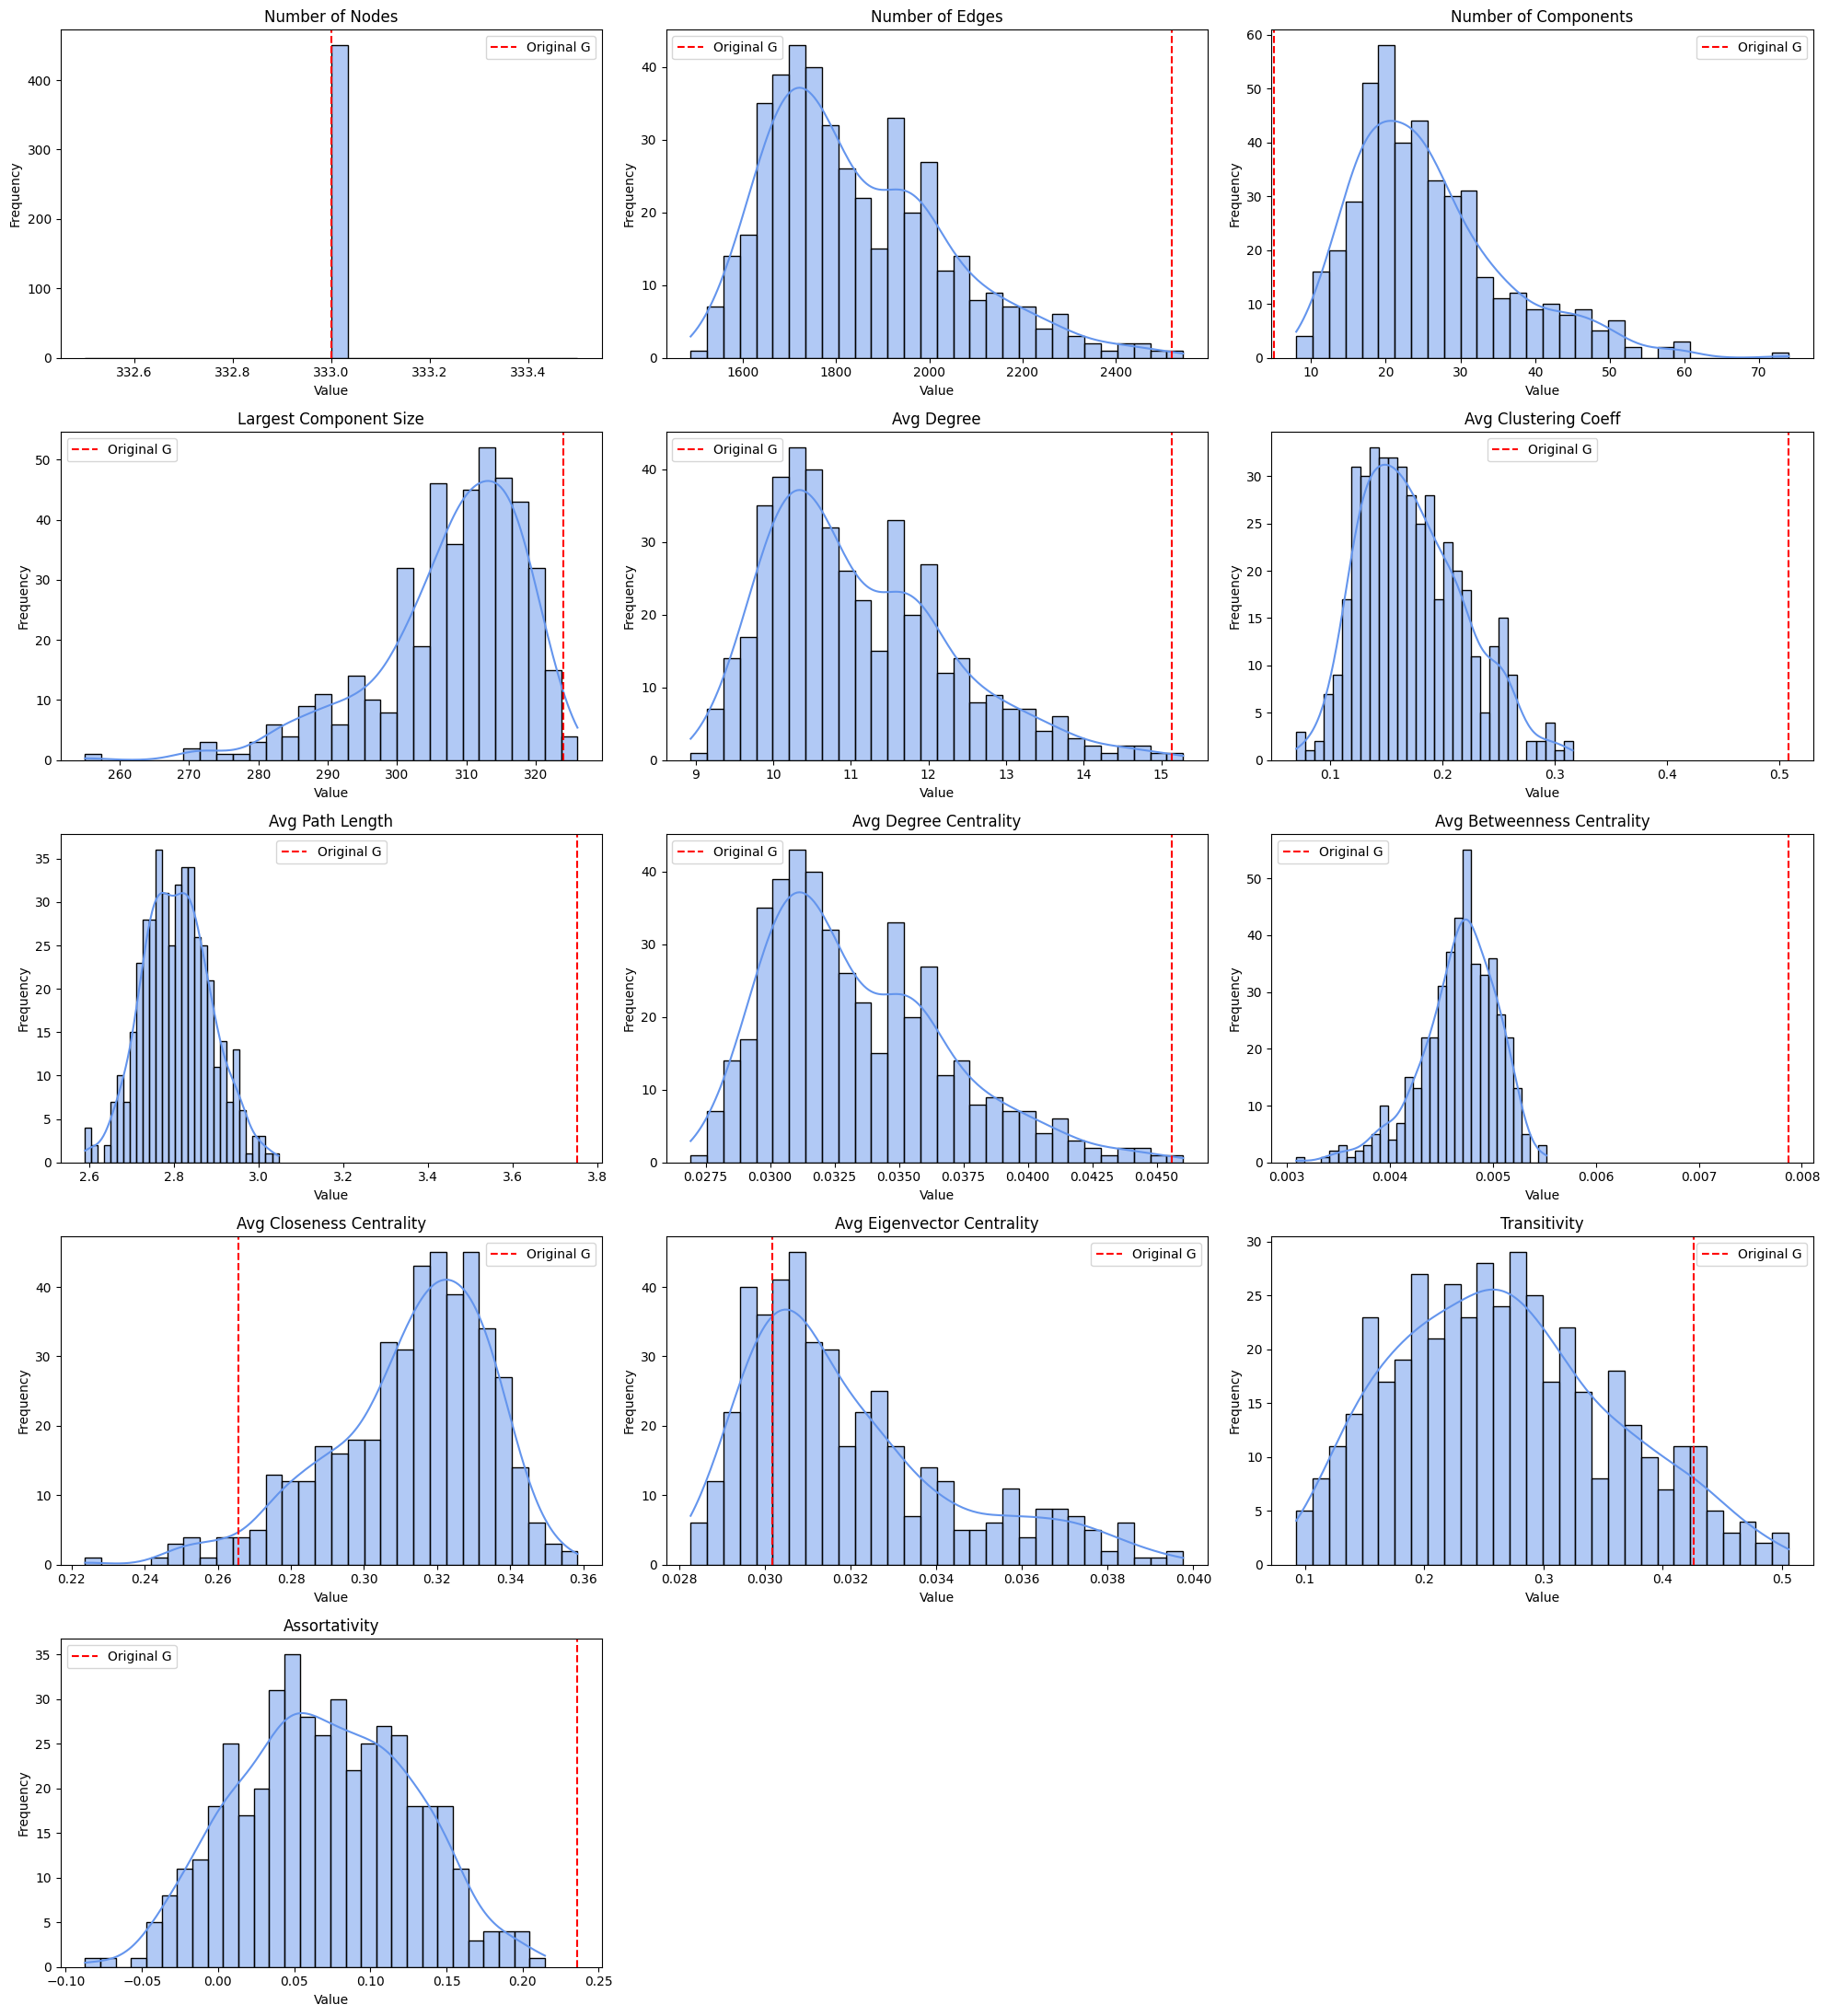

Computing node-level metrics: 100%|██████████| 450/450 [03:42<00:00,  2.02it/s]


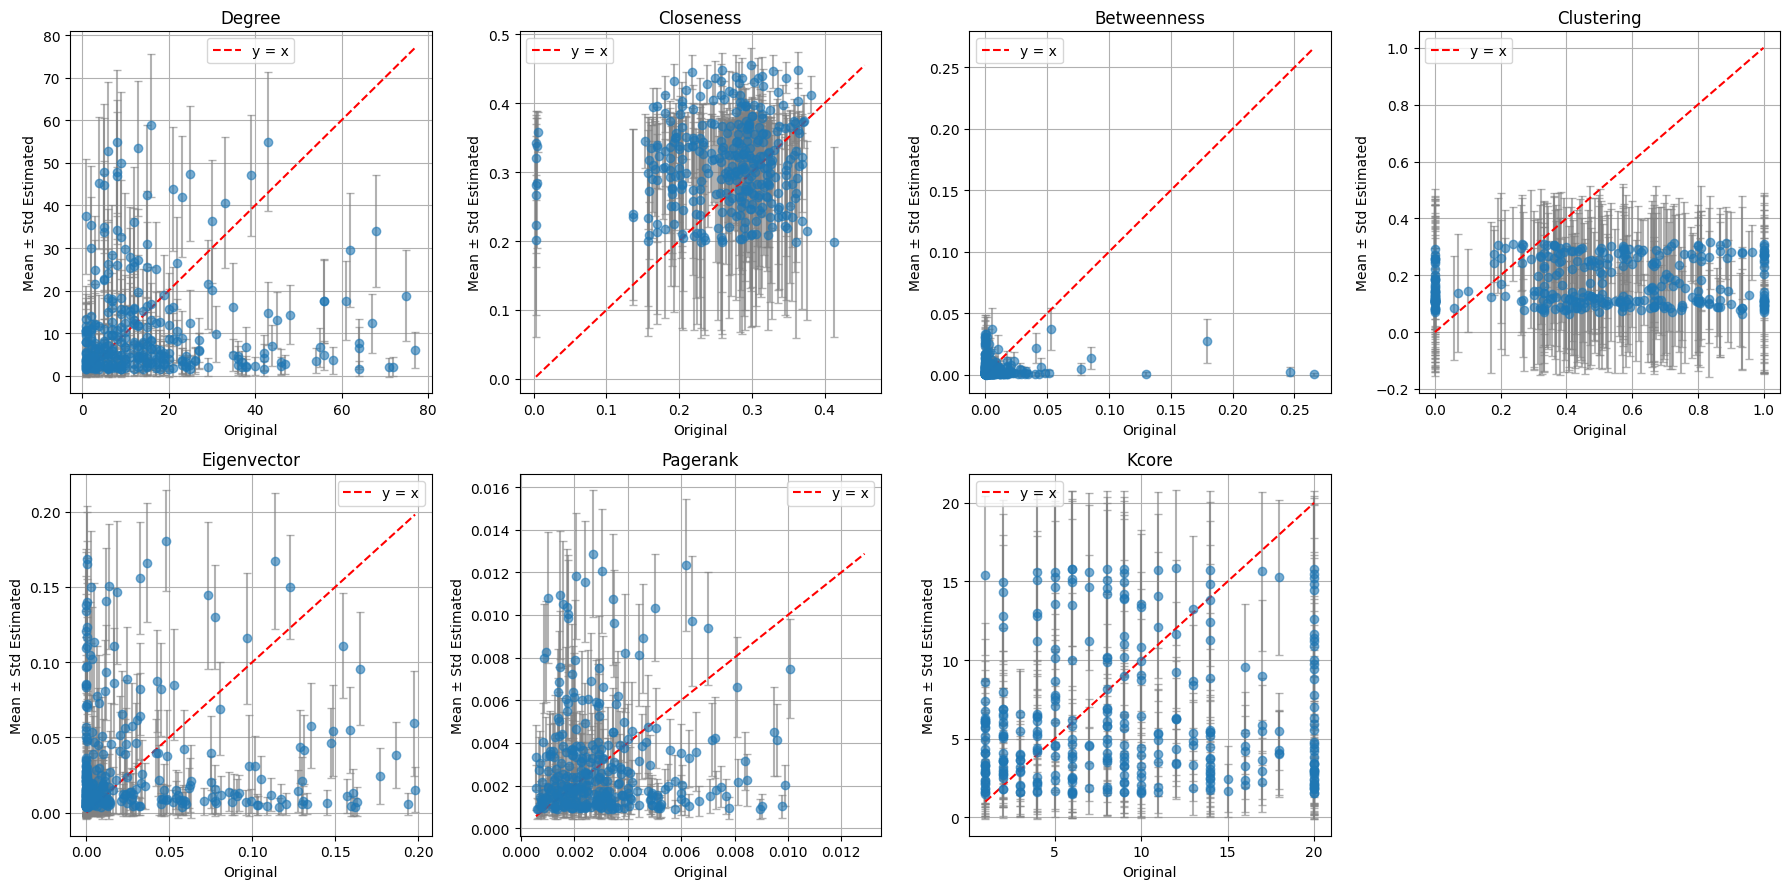

=== Pearson correlations between original and mean estimated node metrics ===
closeness      0.067543
clustering     0.064670
kcore          0.062206
betweenness    0.055851
degree         0.029426
eigenvector    0.027314
pagerank       0.024097
dtype: float64
Diagnostics before Adamic-Adar completed.


In [9]:
# diagnosis before Adamic-Adar

diagnostics_folder = os.path.join(output_folder, "diagnostics_before_adamic_adar")
os.makedirs(diagnostics_folder, exist_ok=True)

# ------------------------------------------------------------
# Safety check: node alignment
# ------------------------------------------------------------

original_nodes = set(G_original.nodes())

for i, G_syn in enumerate(synthetic_graphs):
    if set(G_syn.nodes()) != original_nodes:
        print(f"Warning: synthetic graph {i} does not have exactly the same nodes as G_original")

# ------------------------------------------------------------
# Graph-level diagnostics
# ------------------------------------------------------------

df_graph_metrics = compute_graph_level_metrics(synthetic_graphs)
true_graph_metrics = compute_true_graph_metrics(G_original)

df_graph_metrics.to_csv(
    os.path.join(diagnostics_folder, "synthetic_graph_level_metrics.csv"),
    index=False
)

pd.Series(true_graph_metrics).to_csv(
    os.path.join(diagnostics_folder, "original_graph_level_metrics.csv")
)

print("=== Original graph metrics ===")
print(pd.Series(true_graph_metrics))

plot_graph_metric_distributions(df_graph_metrics, true_graph_metrics)

# ------------------------------------------------------------
# Node-level diagnostics
# ------------------------------------------------------------

metrics_original = compute_node_level_metrics(G_original)
estimated_metrics = compute_estimated_node_metrics(synthetic_graphs)

with open(os.path.join(diagnostics_folder, "synthetic_node_metrics.pkl"), "wb") as f:
    pickle.dump(estimated_metrics, f)

estimated_stats, df_estimated_means = summarize_estimated_node_metrics(estimated_metrics)

df_estimated_means.to_csv(
    os.path.join(diagnostics_folder, "synthetic_node_metric_means.csv")
)

plot_node_metric_scatter(metrics_original, estimated_stats)

corr_summary = compute_node_metric_correlations(
    metrics_original,
    df_estimated_means
)

print("=== Pearson correlations between original and mean estimated node metrics ===")
print(corr_summary)

corr_summary.to_csv(
    os.path.join(diagnostics_folder, "node_metric_correlations.csv")
)

error_metrics = compute_node_metric_errors(
    metrics_original,
    df_estimated_means
)

print("Diagnostics before Adamic-Adar completed.")

In [10]:
# NSUM + Acamic-Adar
degree_estimates = estimate_degrees_nsum(
    ard_matrix=ard_matrix,
    membership_matrix=membership_matrix,
    method="mean_of_ratios"
)

target_edges = estimate_total_edges_from_degrees(
    degree_estimates=degree_estimates,
    n_nodes=n_nodes
)

print("Estimated target number of edges:", target_edges)

augmented_graphs, added_edges_df = augment_graphs_with_adamic_adar(
    graphs=synthetic_graphs,
    target_edges=target_edges
)

print(added_edges_df.describe())

Estimated target number of edges: 2489


Applying Adamic-Adar: 100%|██████████| 450/450 [01:49<00:00,  4.10it/s]

         graph_id  original_edges  target_edges  added_edges  final_edges
count  450.000000      450.000000         450.0   450.000000   450.000000
mean   225.500000     1846.591111        2489.0   642.542222  2489.133333
std    130.048068      195.261955           0.0   194.804337     2.602894
min      1.000000     1488.000000        2489.0     0.000000  2489.000000
25%    113.250000     1699.250000        2489.0   521.000000  2489.000000
50%    225.500000     1798.500000        2489.0   690.500000  2489.000000
75%    337.750000     1968.000000        2489.0   789.750000  2489.000000
max    450.000000     2544.000000        2489.0  1001.000000  2544.000000


In [11]:
# save outputs

save_augmented_graphs(
    augmented_graphs,
    os.path.join(output_folder, "graphs_adamic_adar_nsum.pkl")
)

save_added_edges_info(
    added_edges_df,
    os.path.join(output_folder, "adamic_adar_added_edges_info.csv")
)

print("Saved augmented graphs and edge-addition summary.")

Saved augmented graphs and edge-addition summary.


### Graph-level después de Academic-Adar

Computing graph-level metrics: 100%|██████████| 450/450 [05:47<00:00,  1.29it/s]


=== Original graph metrics ===
Number of Nodes                333.000000
Number of Edges               2519.000000
Number of Components             5.000000
Largest Component Size         324.000000
Avg Degree                      15.129129
Avg Clustering Coeff             0.508245
Avg Path Length                  3.752742
Avg Degree Centrality            0.045570
Avg Betweenness Centrality       0.007872
Avg Closeness Centrality         0.265667
Avg Eigenvector Centrality       0.030162
Transitivity                     0.425869
Assortativity                    0.236039
dtype: float64


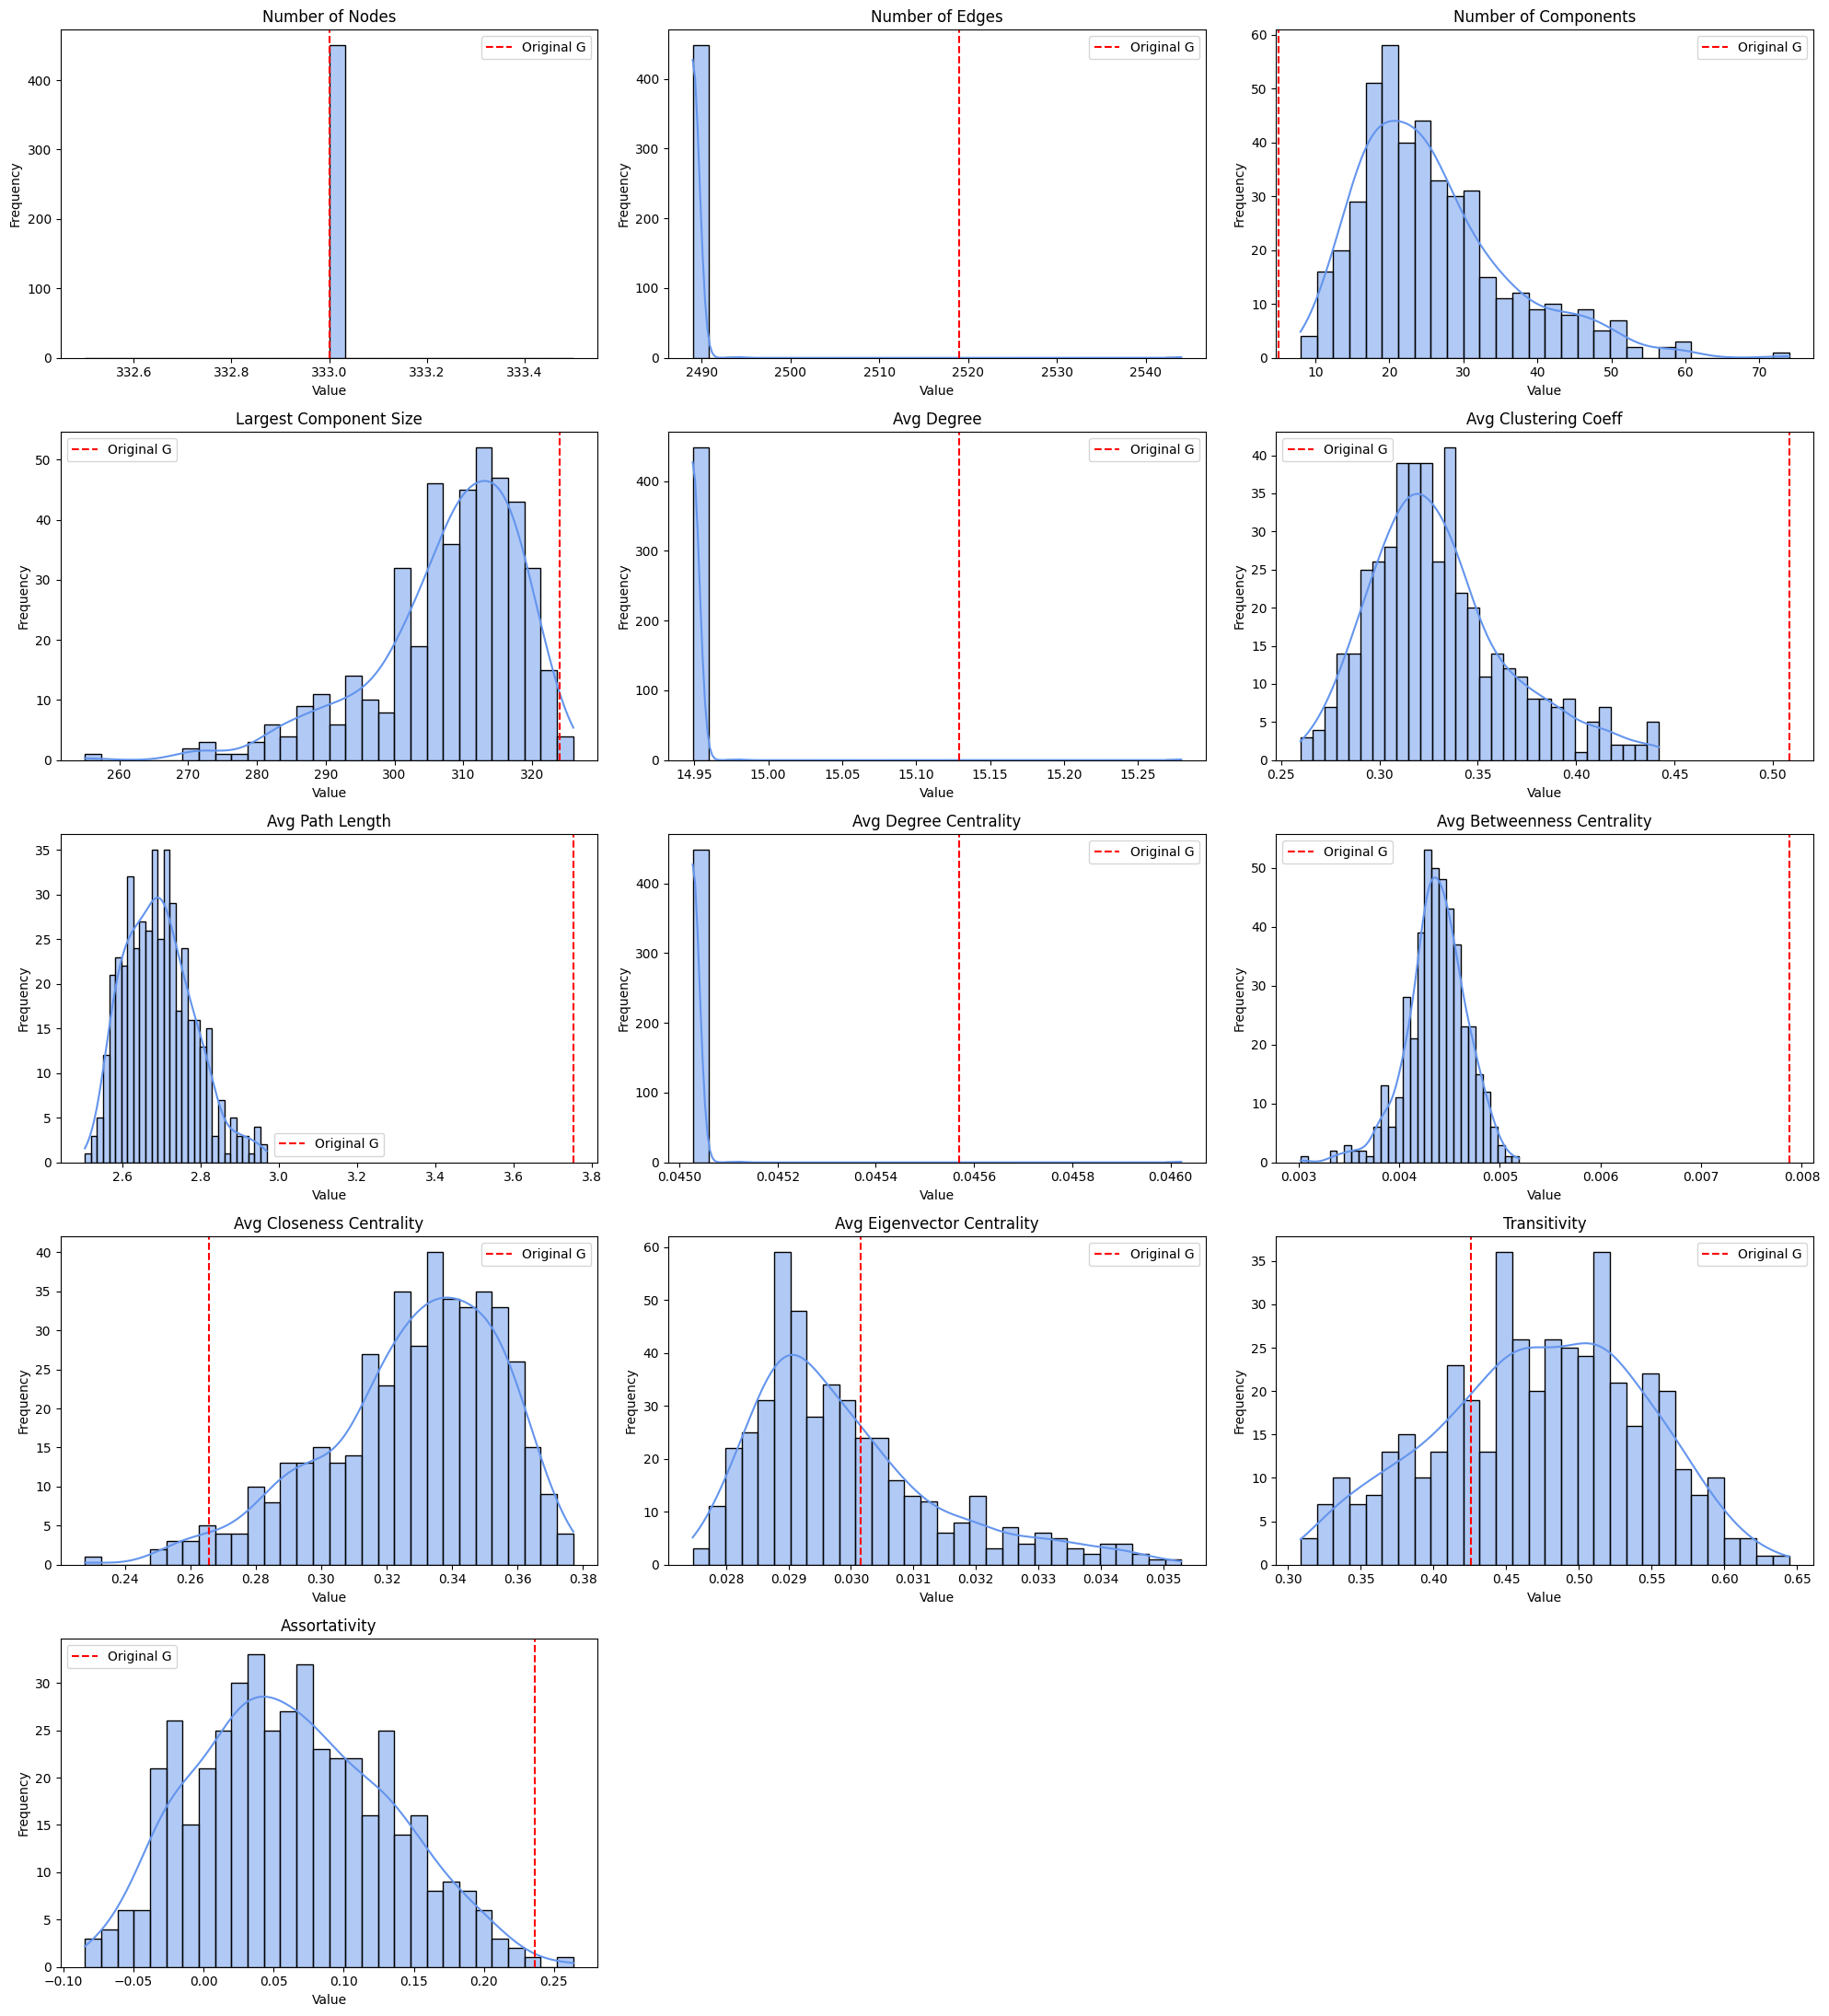

Diagnostics after Adamic-Adar completed.


In [12]:
diagnostics_after_folder = os.path.join(output_folder, "diagnostics_after_adamic_adar")
os.makedirs(diagnostics_after_folder, exist_ok=True)

# ------------------------------------------------------------
# Safety check: node alignment
# ------------------------------------------------------------

original_nodes = set(G_original.nodes())

for i, G_aug in enumerate(augmented_graphs):
    if set(G_aug.nodes()) != original_nodes:
        print(f"Warning: augmented graph {i} does not have exactly the same nodes as G_original")

# ------------------------------------------------------------
# Graph-level diagnostics AFTER Adamic-Adar
# ------------------------------------------------------------

df_graph_metrics_after = compute_graph_level_metrics(augmented_graphs)

true_graph_metrics = compute_true_graph_metrics(G_original)

df_graph_metrics_after.to_csv(
    os.path.join(diagnostics_after_folder, "augmented_graph_level_metrics.csv"),
    index=False
)

pd.Series(true_graph_metrics).to_csv(
    os.path.join(diagnostics_after_folder, "original_graph_level_metrics.csv")
)

print("=== Original graph metrics ===")
print(pd.Series(true_graph_metrics))

plot_graph_metric_distributions(
    df_graph_metrics_after,
    true_graph_metrics
)

print("Diagnostics after Adamic-Adar completed.")

### Node-level después de Academic-Adar

Computing node-level metrics: 100%|██████████| 450/450 [04:24<00:00,  1.70it/s]


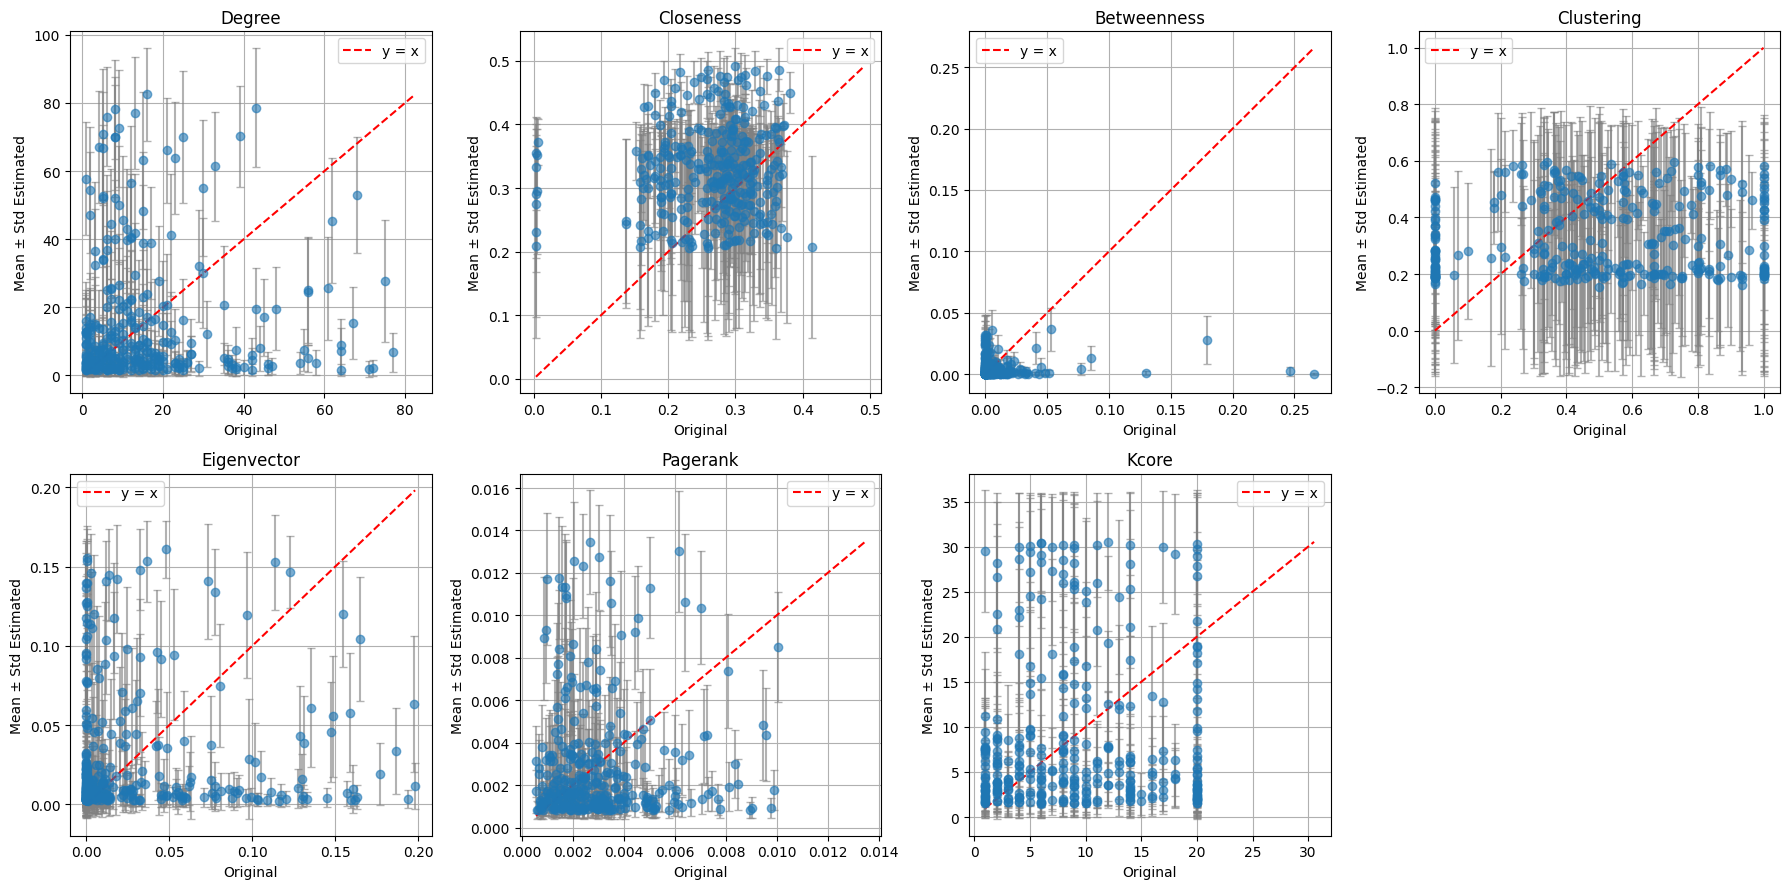

=== Pearson correlations AFTER Adamic-Adar ===
closeness      0.070449
clustering     0.066566
kcore          0.064098
betweenness    0.061208
degree         0.033518
pagerank       0.029557
eigenvector    0.027342
dtype: float64
Diagnostics after Adamic-Adar completed.


In [13]:
metrics_original = compute_node_level_metrics(G_original)

estimated_metrics_after = compute_estimated_node_metrics(augmented_graphs)

with open(os.path.join(diagnostics_after_folder, "augmented_node_metrics.pkl"), "wb") as f:
    pickle.dump(estimated_metrics_after, f)

estimated_stats_after, df_estimated_means_after = summarize_estimated_node_metrics(
    estimated_metrics_after
)

df_estimated_means_after.to_csv(
    os.path.join(diagnostics_after_folder, "augmented_node_metric_means.csv")
)

plot_node_metric_scatter(metrics_original, estimated_stats_after)

corr_summary_after = compute_node_metric_correlations(
    metrics_original,
    df_estimated_means_after
)

print("=== Pearson correlations AFTER Adamic-Adar ===")
print(corr_summary_after)

corr_summary_after.to_csv(
    os.path.join(diagnostics_after_folder, "node_metric_correlations_after.csv")
)

error_metrics_after = compute_node_metric_errors(
    metrics_original,
    df_estimated_means_after
)

print("Diagnostics after Adamic-Adar completed.")